# Step 1: Data checks

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing
**Course:** DT8013 Data Mining, Halmstad University

This notebook checks the UCI Bike Sharing data before any analysis. Data preparation is the first stage of the data mining process (Introduction, Slides 32 to 33, 42). Each check below states what is tested, why it matters for the project, and what is done about it. The notebook ends by saving a cleaned hourly file that later steps build on.

**Checks**
1. Structure: types, duplicates, NaN values
2. Internal consistency: totals, calendar fields, season coding
3. Missing hours
4. Sensor errors in the weather columns
5. Rare categories
6. Growth between 2011 and 2012

The data is expected in `Bike-Sharing-Dataset/` next to this notebook (the unzipped UCI download).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("Bike-Sharing-Dataset")
OUT_FILE = Path("hour_clean.csv")

# One colour per meaning, used consistently in every figure.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
pd.set_option("display.width", 140)

hour = pd.read_csv(DATA_DIR / "hour.csv", parse_dates=["dteday"])
day = pd.read_csv(DATA_DIR / "day.csv", parse_dates=["dteday"])
print(f"hour.csv: {hour.shape[0]:,} rows x {hour.shape[1]} columns")
print(f"day.csv:  {day.shape[0]:,} rows x {day.shape[1]} columns")
hour.head()

hour.csv: 17,379 rows x 17 columns
day.csv:  731 rows x 16 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 1. Structure: types, duplicates and NaN values

Every column should have the expected type, and each (date, hour) pair should appear once. A duplicate hour would double count rentals.

In [2]:
print(hour.dtypes.to_string(), "\n")
print("NaN values in hour.csv:", int(hour.isna().sum().sum()))
print("NaN values in day.csv: ", int(day.isna().sum().sum()))
print("Duplicate (date, hour) pairs:", int(hour.duplicated(["dteday", "hr"]).sum()))

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64 

NaN values in hour.csv: 0
NaN values in day.csv:  0
Duplicate (date, hour) pairs: 0


## 2. Internal consistency

Three things must hold if the files are internally consistent:

- `cnt` equals `casual + registered` in both files.
- The hourly counts summed per day equal `day.csv`.
- The calendar columns agree with the date: `weekday` matches the actual weekday, and `workingday` is 1 exactly when the day is neither a weekend nor a holiday.

The season coding is also checked, because later steps group days by season.

In [3]:
checks = {
    "hour: cnt == casual + registered": (hour.cnt == hour.casual + hour.registered).all(),
    "day:  cnt == casual + registered": (day.cnt == day.casual + day.registered).all(),
}

daily_from_hours = hour.groupby("dteday")[["casual", "registered", "cnt"]].sum()
day_idx = day.set_index("dteday")
checks["sum of hours == day.csv (all three counts)"] = (
    daily_from_hours[["casual", "registered", "cnt"]] == day_idx[["casual", "registered", "cnt"]]
).all().all()

# pandas: Monday=0 ... Sunday=6; dataset: Sunday=0 ... Saturday=6
checks["weekday matches the date"] = (day.weekday == (day.dteday.dt.dayofweek + 1) % 7).all()
is_weekend = day.weekday.isin([0, 6])
checks["workingday == not (weekend or holiday)"] = (
    day.workingday == (~is_weekend & (day.holiday == 0)).astype(int)
).all()

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

PASS  hour: cnt == casual + registered
PASS  day:  cnt == casual + registered
PASS  sum of hours == day.csv (all three counts)
PASS  weekday matches the date
PASS  workingday == not (weekend or holiday)


In [4]:
# Season is coded by astronomical dates (equinox and solstice), not by month.
# March, June, September and December are therefore split between two seasons.
pd.crosstab(day.mnth, day.season).rename_axis(index="month", columns="season")

season,1,2,3,4
month,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


**Result.** All consistency checks pass. Note that `season` follows the astronomical calendar (season 1 = winter starts around 21 December), so it is not the same as grouping months. This matters when calendar contexts are built in Step 7.

## 3. Missing hours

731 days x 24 hours = 17,544 hours, but `hour.csv` has fewer rows. There are no NaN values, so the missing data is **whole rows that are absent**, which a NaN check does not catch.

The key question is what a missing row means. Either the data was lost (and should be estimated), or nobody rented a bike that hour (and the true count is 0). Two observations decide this:

- The smallest `cnt` in the file is 1. An hour with zero rentals never appears, even though zero is common at night in a bike-sharing system.
- Missing hours cluster at 2 to 5 a.m., when demand is lowest.

In [5]:
full_grid = pd.MultiIndex.from_product([day.dteday, range(24)], names=["dteday", "hr"])
present = pd.MultiIndex.from_frame(hour[["dteday", "hr"]])
missing = full_grid.difference(present).to_frame(index=False)
missing_per_day = missing.groupby("dteday").size()

print(f"Expected hours: {len(full_grid):,}   present: {len(hour):,}   missing: {len(missing):,}")
print(f"Days with at least one missing hour: {missing_per_day.size} of {len(day)}")
print(f"Smallest cnt in the file: {hour.cnt.min()}  (an hour with 0 rentals never appears)")

Expected hours: 17,544   present: 17,379   missing: 165
Days with at least one missing hour: 76 of 731
Smallest cnt in the file: 1  (an hour with 0 rentals never appears)


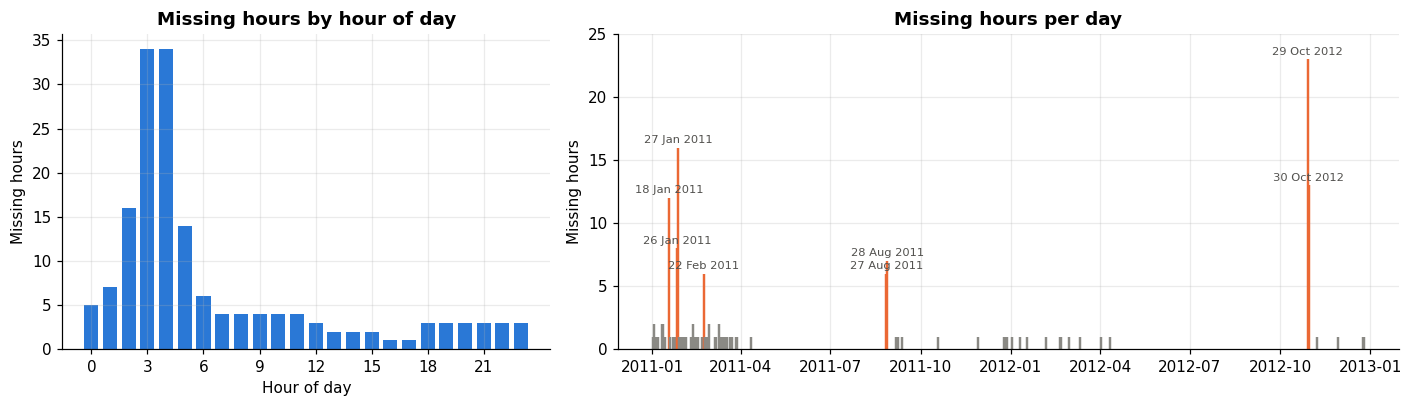

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})

by_hour = missing.hr.value_counts().reindex(range(24), fill_value=0)
axes[0].bar(by_hour.index, by_hour.values, color=BLUE, width=0.75)
axes[0].set(title="Missing hours by hour of day", xlabel="Hour of day", ylabel="Missing hours",
            xticks=range(0, 24, 3))

long_gap = missing_per_day >= 6
axes[1].vlines(missing_per_day.index, 0, missing_per_day.values,
               color=np.where(long_gap, ORANGE, GREY), linewidth=1.6)
axes[1].set(title="Missing hours per day", ylabel="Missing hours", ylim=(0, 25))
for d, n in missing_per_day[long_gap].items():
    axes[1].annotate(d.strftime("%d %b %Y"), (d, n), xytext=(0, 3), textcoords="offset points",
                     ha="center", fontsize=7.5, color="#52514e")
fig.tight_layout()
plt.show()

In [7]:
# Days with 6 or more missing hours: these are long gaps, not quiet nights.
long_days = missing_per_day[long_gap].rename("missing_hours").to_frame()
long_days["missing_hours_list"] = missing[missing.dteday.isin(long_days.index)].groupby("dteday").hr.apply(
    lambda h: f"{h.min()}-{h.max()}" if (h.max() - h.min() + 1) == len(h) else ", ".join(map(str, h)))
long_days = long_days.join(day_idx[["cnt", "weathersit", "workingday"]])
long_days

,missing_hours,missing_hours_list,cnt,weathersit,workingday
dteday,,,,,
2011-01-18,12,0-11,683,2,1
2011-01-26,8,"3, 4, 18, 19, 20, 21, 22, 23",506,3,1
2011-01-27,16,0-15,431,1,1
2011-02-22,6,0-5,1450,1,1
2011-08-27,6,18-23,1115,2,0
2011-08-28,7,0-6,4334,1,0
2012-10-29,23,1-23,22,3,1
2012-10-30,13,0-12,1096,2,1


**Interpretation.**

- **Short gaps (1 to 2 hours, almost all between 2 and 5 a.m.)** are hours with zero rentals that were not written to the file. They are filled with `cnt = 0`. Interpolating them would invent rentals that did not happen.
- **Long gaps** fall on a few specific dates. Two of them match well-known storms in Washington DC: 27 to 28 August 2011 (Hurricane Irene) and 29 to 30 October 2012 (Hurricane Sandy, when the system had almost no rentals). The January 2011 gaps also look weather-related (`weathersit` is 3 on 26 January). These need checking against outside sources when the reference event list is built (Evaluation plan).
- Long gaps are also filled with 0, because the daily totals in `day.csv` confirm no rentals were recorded. They are **flagged** (`hour_was_missing`), because these days are exactly the kind of anomaly the project wants to detect, so they must not be cleaned away.

This means the missing rows are not a data quality problem to hide. They are the first evidence of real events in the data.

## 4. Sensor errors in the weather columns

Weather columns are normalized to 0 to 1 (UCI documentation). They are converted back to physical units, so impossible values are easier to see:

- temperature in °C = temp x 47 - 8
- feels-like temperature in °C = atemp x 66 - 16
- humidity in % = hum x 100
- wind speed in km/h = windspeed x 67

A stuck sensor shows up as a value that stays exactly constant for a whole day. Real weather changes from hour to hour. The check below looks for days where a weather column has only one distinct value across at least 20 recorded hours.

In [8]:
hour["temp_c"] = hour.temp * 47 - 8
hour["atemp_c"] = hour.atemp * 66 - 16
hour["hum_pct"] = hour.hum * 100
hour["wind_kmh"] = hour.windspeed * 67

def stuck_days(df, col, min_hours=20):
    # Days where a column never changes over many hours: a sign of a frozen sensor.
    g = df.groupby("dteday")[col].agg(["nunique", "size", "first"])
    return g[(g["nunique"] == 1) & (g["size"] >= min_hours)]

for col in ["temp_c", "atemp_c", "hum_pct", "wind_kmh"]:
    s = stuck_days(hour, col)
    print(f"{col:9s}: {len(s)} stuck day(s)", "" if s.empty else s[["first", "size"]].to_dict("index"))

temp_c   : 1 stuck day(s) {Timestamp('2011-09-06 00:00:00'): {'first': 17.380000000000003, 'size': 23}}
atemp_c  : 3 stuck day(s) {Timestamp('2011-09-06 00:00:00'): {'first': 18.0032, 'size': 23}, Timestamp('2012-08-17 00:00:00'): {'first': -0.0015999999999998238, 'size': 24}, Timestamp('2012-12-29 00:00:00'): {'first': -0.0015999999999998238, 'size': 24}}
hum_pct  : 1 stuck day(s) {Timestamp('2011-03-10 00:00:00'): {'first': 0.0, 'size': 22}}
wind_kmh : 0 stuck day(s) 


A constant value is a screening signal, not proof. The resolution of the data is coarse (one step of `temp` is about 1 °C), so a steady rainy day can legitimately show one value. A stuck day is therefore treated as a **sensor error only if the value is also physically implausible**:

- humidity of 0% is impossible in outdoor air
- a feels-like temperature more than 10 °C away from the actual temperature, all day, is implausible for this climate

In [9]:
def daily_gap(df, d):
    x = df[df.dteday == d]
    return (x.atemp_c - x.temp_c).abs().mean()

review = []
for col in ["temp_c", "atemp_c", "hum_pct"]:
    for d, row in stuck_days(hour, col).iterrows():
        if col == "hum_pct":
            error = row["first"] == 0
            reason = "humidity of 0% is impossible" if error else "plausible value"
        else:
            gap = daily_gap(hour, d)
            error = col == "atemp_c" and gap > 10
            reason = f"mean |feels-like minus temperature| = {gap:.1f} °C"
        review.append({"date": d.date(), "column": col, "stuck value": round(row["first"], 1),
                       "reason": reason, "decision": "sensor error, replace" if error else "keep, note"})
review = pd.DataFrame(review)
SENSOR_ERRORS = {c: pd.to_datetime(review.loc[(review.column == c) & review.decision.str.startswith("sensor"), "date"]).tolist()
                 for c in ["hum_pct", "atemp_c"]}
review

,date,column,stuck value,reason,decision
0,2011-09-06,temp_c,17.4,mean |feels-like minus temperature| = 0.6 °C,"keep, note"
1,2011-09-06,atemp_c,18.0,mean |feels-like minus temperature| = 0.6 °C,"keep, note"
2,2012-08-17,atemp_c,-0.0,mean |feels-like minus temperature| = 26.0 °C,"sensor error, replace"
3,2012-12-29,atemp_c,-0.0,mean |feels-like minus temperature| = 3.9 °C,"keep, note"
4,2011-03-10,hum_pct,0.0,humidity of 0% is impossible,"sensor error, replace"


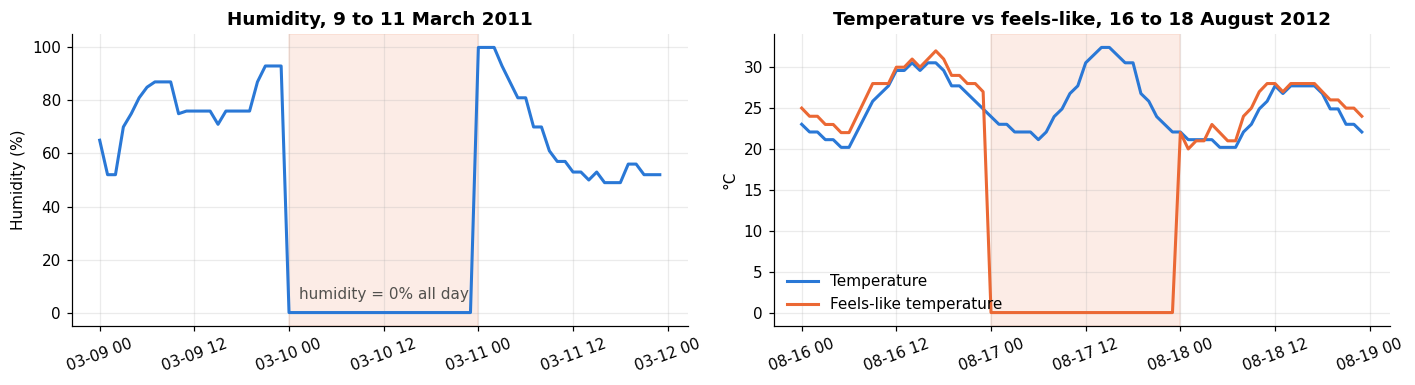

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))

win = hour[hour.dteday.between("2011-03-09", "2011-03-11")]
axes[0].plot(win.dteday + pd.to_timedelta(win.hr, "h"), win.hum_pct, color=BLUE, linewidth=2)
axes[0].set(title="Humidity, 9 to 11 March 2011", ylabel="Humidity (%)")
axes[0].axvspan(pd.Timestamp("2011-03-10"), pd.Timestamp("2011-03-11"), color=ORANGE, alpha=0.12)
axes[0].annotate("humidity = 0% all day", (pd.Timestamp("2011-03-10 12:00"), 5), ha="center", color="#52514e")

win = hour[hour.dteday.between("2012-08-16", "2012-08-18")]
t = win.dteday + pd.to_timedelta(win.hr, "h")
axes[1].plot(t, win.temp_c, color=BLUE, linewidth=2, label="Temperature")
axes[1].plot(t, win.atemp_c, color=ORANGE, linewidth=2, label="Feels-like temperature")
axes[1].axvspan(pd.Timestamp("2012-08-17"), pd.Timestamp("2012-08-18"), color=ORANGE, alpha=0.12)
axes[1].set(title="Temperature vs feels-like, 16 to 18 August 2012", ylabel="°C")
axes[1].legend(frameon=False, loc="lower left")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
fig.tight_layout()
plt.show()

**Two sensor errors, two ambiguous days.**

- **10 March 2011, humidity.** Humidity is 0% for the whole day, which is impossible in outdoor air (and `weathersit` = 3, light rain, that day). Sensor error.
- **17 August 2012, feels-like temperature.** `atemp` stays at about 0 °C all day while the actual temperature is in the mid-20s °C in August. Sensor error.
- **6 September 2011, temperature** and **29 December 2012, feels-like temperature** are constant all day, but the values are plausible: humidity and wind still vary, and the feels-like and actual temperatures agree within a few degrees. They are kept and mentioned as a limitation.

Rental counts on these days are **not** touched: only the faulty weather values are replaced, and each replacement is flagged.

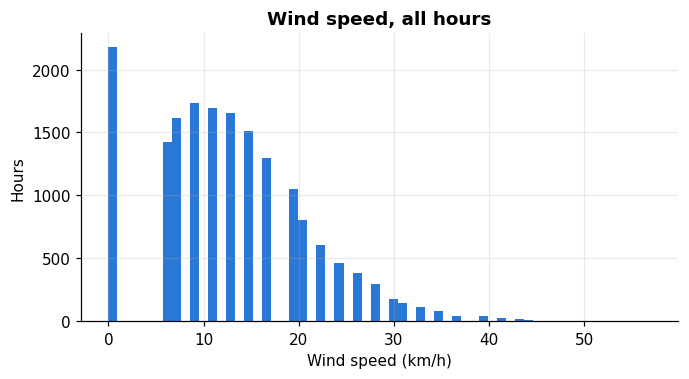

Hours with wind = 0: 12.5%
Smallest recorded values (km/h): [0. 6. 7.]


In [11]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(hour.wind_kmh, bins=60, color=BLUE)
ax.set(title="Wind speed, all hours", xlabel="Wind speed (km/h)", ylabel="Hours")
plt.show()

levels = np.sort(hour.windspeed.unique())[:3] * 67
print(f"Hours with wind = 0: {(hour.windspeed == 0).mean():.1%}")
print(f"Smallest recorded values (km/h): {np.round(levels, 1)}")

**Wind speed = 0 in about 1 in 8 hours.** No value lies between 0 and about 6 km/h. This is consistent with an anemometer that reports calm below a threshold, but it could also be missing data coded as 0. It cannot be decided from the data alone, so the values are **kept as they are** and the limitation is noted. Wind is not a core feature of the project, so this choice has little effect.

## 5. Rare categories

`weathersit` has four levels: 1 = clear, 2 = mist, 3 = light rain or snow, 4 = heavy rain, ice or thunderstorm. A context group (Step 7) needs enough observations to estimate a typical profile.

In [12]:
print(hour.weathersit.value_counts().sort_index().rename("hours").to_string())
print()
print(hour.loc[hour.weathersit == 4, ["dteday", "hr", "cnt", "temp_c", "hum_pct"]].to_string(index=False))

weathersit
1    11413
2     4544
3     1419
4        3

    dteday  hr  cnt  temp_c  hum_pct
2011-01-26  16   36    2.34     93.0
2012-01-09  18  164    1.40     86.0
2012-01-21   1   23   -1.42     86.0


**Decision.** Level 4 occurs in only 3 hours over two years, which is too few for any group statistic. It is merged into level 3 ("bad weather"). The original value is kept in `weathersit_raw` so the merge can be undone.

## 6. Growth between 2011 and 2012

If demand grows strongly over the two years, clustering raw daily counts would separate 2011 from 2012 instead of commuting days from leisure days (Outline, Step 3). A 30-day rolling median shows the underlying level, and seasonal-trend decomposition (Time Series Analysis, Slide 27) follows in Step 3.

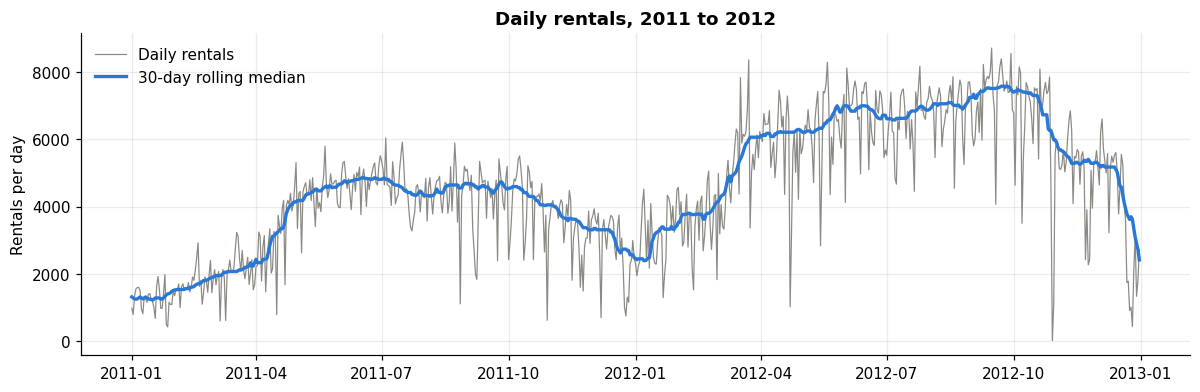

          mean  median      sum
dteday                         
2011    3406.0  3740.0  1243103
2012    5600.0  5927.0  2049576

Mean daily rentals grew by 64% from 2011 to 2012.


In [13]:
daily = day.set_index("dteday").cnt
level = daily.rolling(30, center=True, min_periods=15).median()

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(daily.index, daily, color=GREY, linewidth=0.8, label="Daily rentals")
ax.plot(level.index, level, color=BLUE, linewidth=2.2, label="30-day rolling median")
ax.set(title="Daily rentals, 2011 to 2012", ylabel="Rentals per day")
ax.legend(frameon=False, loc="upper left")
plt.show()

by_year = day.groupby(day.dteday.dt.year).cnt.agg(["mean", "median", "sum"]).round(0)
print(by_year.to_string())
growth = by_year.loc[2012, "mean"] / by_year.loc[2011, "mean"] - 1
print(f"\nMean daily rentals grew by {growth:.0%} from 2011 to 2012.")

**Result.** Demand is much higher in 2012 than in 2011, on top of the seasonal cycle. Later steps must therefore separate the **shape** of a day (how rentals are spread over 24 hours) from its **level** (how many rentals in total). Otherwise the clusters would mostly encode the year.

## 7. Apply the fixes and save

All fixes from the checks above, in one place:

| Issue | Fix | Flag column |
| --- | --- | --- |
| Missing hour rows | Add the row with `casual = registered = cnt = 0`; calendar fields from `day.csv`; weather interpolated from neighbouring hours | `hour_was_missing` |
| Humidity stuck at 0 (10 Mar 2011) | Replace with the mean of the same hour on the previous and next day | `hum_imputed` |
| Feels-like temperature stuck (17 Aug 2012) | Replace with a linear fit of `atemp` on `temp` from all other hours | `atemp_imputed` |
| `weathersit` = 4 (3 hours) | Merge into 3 | original kept in `weathersit_raw` |
| Wind speed = 0 | Kept, limitation noted | none |

In [14]:
clean = hour.drop(columns=["instant", "temp_c", "atemp_c", "hum_pct", "wind_kmh"]).set_index(["dteday", "hr"])
clean = clean.reindex(full_grid)
clean["hour_was_missing"] = clean.cnt.isna()

# Missing rows are hours with no rentals (see check 3).
clean[["casual", "registered", "cnt"]] = clean[["casual", "registered", "cnt"]].fillna(0).astype(int)

# Calendar fields are properties of the date, so they come from day.csv.
calendar_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday"]
clean = clean.drop(columns=calendar_cols).join(day.set_index("dteday")[calendar_cols], on="dteday")

clean = clean.reset_index()
# Weather is continuous in time: interpolate numeric columns, carry the nearest category.
for col in ["temp", "atemp", "hum", "windspeed"]:
    clean[col] = clean[col].interpolate(limit_direction="both")
clean["weathersit"] = clean["weathersit"].ffill().bfill().astype(int)

In [15]:
# Humidity stuck at 0: use the same hour on the neighbouring days.
clean["hum_imputed"] = False
for d in SENSOR_ERRORS["hum_pct"]:
    mask = clean.dteday == d
    neighbours = clean[clean.dteday.isin([d - pd.Timedelta(days=1), d + pd.Timedelta(days=1)])]
    clean.loc[mask, "hum"] = clean.loc[mask, "hr"].map(neighbours.groupby("hr").hum.mean())
    clean.loc[mask, "hum_imputed"] = True

# Feels-like temperature stuck: predict it from actual temperature using all other hours.
clean["atemp_imputed"] = False
bad_atemp = clean.dteday.isin(SENSOR_ERRORS["atemp_c"])
slope, intercept = np.polyfit(clean.loc[~bad_atemp, "temp"], clean.loc[~bad_atemp, "atemp"], deg=1)
clean.loc[bad_atemp, "atemp"] = slope * clean.loc[bad_atemp, "temp"] + intercept
clean.loc[bad_atemp, "atemp_imputed"] = True

# Rare weather category.
clean["weathersit_raw"] = clean["weathersit"]
clean["weathersit"] = clean["weathersit"].clip(upper=3)

print(f"Humidity values replaced:  {clean.hum_imputed.sum()}")
print(f"Feels-like values replaced: {clean.atemp_imputed.sum()}  (fit: atemp = {slope:.3f} * temp + {intercept:.3f})")

Humidity values replaced:  24
Feels-like values replaced: 24  (fit: atemp = 0.886 * temp + 0.036)


### Verify the cleaned data

The fixes must not change any daily total, and the result must be a complete hourly grid.

In [16]:
after = clean.groupby("dteday")[["casual", "registered", "cnt"]].sum()
final_checks = {
    "complete grid: 731 x 24 rows": len(clean) == len(day) * 24,
    "no NaN values": not clean.isna().any().any(),
    "daily totals unchanged vs day.csv": (after == day_idx[["casual", "registered", "cnt"]]).all().all(),
    "cnt == casual + registered": (clean.cnt == clean.casual + clean.registered).all(),
    "no humidity of 0 left": (clean.hum > 0).all(),
    "weathersit in {1, 2, 3}": clean.weathersit.isin([1, 2, 3]).all(),
}
for name, ok in final_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(final_checks.values()), "A final check failed; do not use the output."

clean.to_csv(OUT_FILE, index=False)
print(f"\nSaved {OUT_FILE} with {len(clean):,} rows and {clean.shape[1]} columns.")

PASS  complete grid: 731 x 24 rows
PASS  no NaN values
PASS  daily totals unchanged vs day.csv
PASS  cnt == casual + registered
PASS  no humidity of 0 left
PASS  weathersit in {1, 2, 3}

Saved hour_clean.csv with 17,544 rows and 20 columns.


## Summary for the report

- **Structure and consistency:** no NaN values, no duplicates, and all internal totals and calendar fields agree.
- **Missing hours:** 165 hours (on 76 days) are absent from `hour.csv`. Short night-time gaps are hours with zero rentals. Long gaps match storm dates (Hurricane Irene in August 2011, Hurricane Sandy in October 2012). They are filled with 0 and flagged, because they are candidate anomalies, not noise.
- **Sensor errors:** a constant-value screen found four stuck days. Two are physically implausible (humidity 0% on 10 March 2011; feels-like about 0 °C on 17 August 2012) and are replaced and flagged. Two are plausible (6 September 2011, 29 December 2012) and are kept. Rental counts are untouched.
- **Wind speed:** 0 in about 1 in 8 hours, possibly a calm threshold or missing data; kept and noted as a limitation.
- **Rare category:** `weathersit` = 4 (3 hours) merged into 3.
- **Trend:** mean daily demand grows strongly from 2011 to 2012, so later steps separate the shape of a day from its level.

Output: `hour_clean.csv`, a complete grid of 17,544 hours with flag columns, used by Step 2 (day matrix).